In [1]:
import pandas as pd

df = pd.read_csv("../data/SeoulBikeData.csv", encoding="latin1")

df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")

df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [2]:
# data only for working days
model_data = df[df["Functioning Day"] == "Yes"].sort_values(["Date", "Hour"])

features = ["Hour", "Temperature(°C)", "Rainfall(mm)"]

x = model_data[features]
y = model_data["Rented Bike Count"]

print("x:", x.shape)
print("y:", y.shape)

x: (8465, 3)
y: (8465,)


In [3]:
# Split data into training (80%) and test (20%) sets
split_index = int(len(x) * 0.8)

x_train = x.iloc[:split_index] # first 80% of data
x_test = x.iloc[split_index:]  # last 20% of data

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Train:", x_train.shape, y_train.shape)
print("Test: ", x_test.shape, y_test.shape)

Train: (6772, 3) (6772,)
Test:  (1693, 3) (1693,)


In [ ]:
# DummyRegressor

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

# Create and train the baseline model
baseline = DummyRegressor(strategy="mean")
baseline.fit(x_train, y_train)

# Predict using test data
y_pred = baseline.predict(x_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)

print(f"Baseline prediction: {y_pred[0]:.2f}")
print(f"Baseline MAE: {mae:.2f}")

Baseline prediction: 687.55
Baseline MAE: 491.51


### Baseline - DummyRegressor

We used DummyRegressor as our baseline. It always predicts the average number of rentals from the training data.  
It does not consider time, temperature, rain or any other features.

**Results:**
- Prediction: 687.55 bikes
- MAE: 491.51 bikes

This means the prediction is wrong by about 492 bikes on average. We will use this result to compare other models.

In [5]:
# Linear Regression
from sklearn.linear_model import LinearRegression

# Train the model
model = LinearRegression()
model.fit(x_train, y_train)

# Predict
linear_pred = model.predict(x_test)

# Evaluate
linear_mae = mean_absolute_error(y_test, linear_pred)

print(f"Baseline MAE: {mae:.2f}")
print(f"Linear Regression MAE: {linear_mae:.2f}")

Baseline MAE: 491.51
Linear Regression MAE: 363.41


Linear Regression works better, but the error is still pretty high. I think it's because the relationship between the features and bike rentals isn't linear.

In [ ]:
# Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

# Train the model
tree = DecisionTreeRegressor(max_depth=5, random_state=42) # TODO try different values
tree.fit(x_train, y_train)

# Predict
tree_pred = tree.predict(x_test)

# Evaluate
tree_mae = mean_absolute_error(y_test, tree_pred)

print(f"Baseline MAE: {mae:.2f}")
print(f"Linear Regression MAE: {linear_mae:.2f}")
print(f"Decision Tree MAE: {tree_mae:.2f}")

Baseline MAE: 491.51
Linear Regression MAE: 363.41
Decision Tree MAE: 309.42


Decision Tree gives a better result, but the error is still pretty high — almost 50% of the average number of rentals.  
We noticed a difference between weekdays and weekends during EDA, so let's try adding this as another feature.

In [10]:
# Add IsWeekend
model_data["IsWeekend"] = (model_data["Date"].dt.day_of_week  >= 5).astype(int)

x_weekend = model_data[features + ["IsWeekend"]]

x_train_weekend = x_weekend.iloc[:split_index]
x_test_weekend = x_weekend.iloc[split_index:]

tree_weekend = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_weekend.fit(x_train_weekend, y_train)

weekend_pred = tree_weekend.predict(x_test_weekend)
weekend_mae = mean_absolute_error(y_test, weekend_pred)

print(f"Original Decision Tree MAE: {tree_mae:.2f}")
print(f"With IsWeekend MAE: {weekend_mae:.2f}")

Original Decision Tree MAE: 309.42
With IsWeekend MAE: 309.93


Adding **IsWeekend** didn't help. The error even increased a little. Maybe the tree is too simple to make good use of this feature.

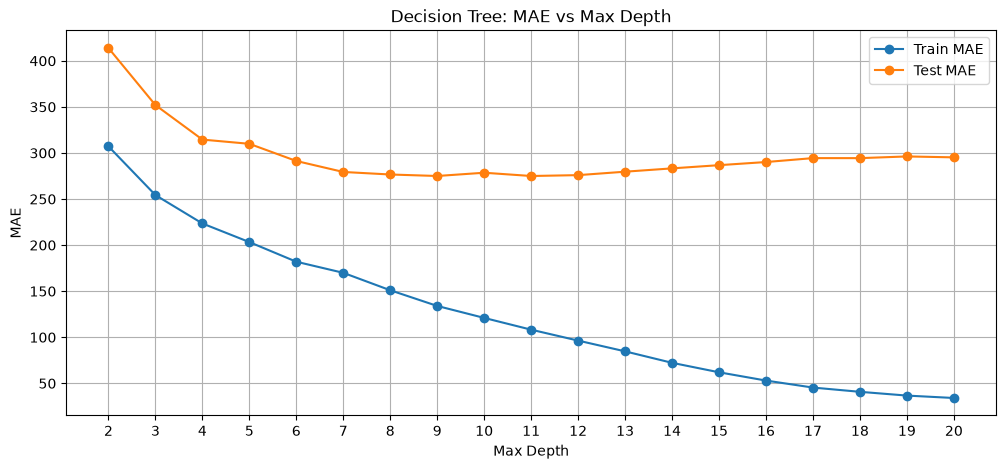

In [ ]:
# Trying different max_depth
import matplotlib.pyplot as plt

train_errors = []
test_errors = []
depths = range(2, 21)

for depth in depths:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(x_train_weekend, y_train)

    train_pred = tree.predict(x_train_weekend)
    test_pred = tree.predict(x_test_weekend)

    train_errors.append(mean_absolute_error(y_train, train_pred))
    test_errors.append(mean_absolute_error(y_test, test_pred))

plt.figure(figsize=(12, 5))
plt.plot(depths, train_errors, marker="o", label="Train MAE")
plt.plot(depths, test_errors, marker="o", label="Test MAE")

plt.title("Decision Tree: MAE vs Max Depth")
plt.xlabel("Max Depth")
plt.ylabel("MAE")
plt.xticks(depths)
plt.legend()
plt.grid(True)
plt.show()

Tested different **max_depth**. The best results were around **9–12**. After that, the training error kept decreasing, but the test error started increasing. This looks like overfitting.